# Problema 3 - Classificação da Qualidade de Vinhos com k-NN

**Objetivo:** classificar vinhos tintos em três categorias de qualidade (**ruim**, **médio** e **bom**) a partir
de 11 medidas físico-químicas, usando o **k-NN** (*k-Nearest Neighbors*).

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/blob/main/Primeira%20Unidade/Projetos/03-knn-wine-quality/src/problema3.ipynb)

**Dataset:** UCI Wine Quality - `winequality-red.csv` (1.599 vinhos tintos).

## 1. Importando as bibliotecas e carregando os dados

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, classification_report
)

plt.rcParams['figure.figsize'] = (8, 4)

O arquivo usa **ponto e vírgula** como separador, por isso `sep=";"`.

In [2]:
# Se o arquivo existir na pasta do projeto, estamos rodando no PC.
# Se não existir (ex.: Google Colab), baixamos o mesmo arquivo do GitHub.
if os.path.exists("../data/winequality-red.csv"):
    caminho_dados = "../data/winequality-red.csv"
    pasta_resultados = "../resultados"
else:
    caminho_dados = "https://raw.githubusercontent.com/FredGregorio/Disciplina-sistemas-inteligentes-2026.2/main/Primeira%20Unidade/Projetos/03-knn-wine-quality/data/winequality-red.csv"
    pasta_resultados = "resultados"

os.makedirs(pasta_resultados, exist_ok=True)   # pasta onde salvamos os gráficos

df = pd.read_csv(caminho_dados, sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print(f"Quantidade de vinhos = {df.shape[0]}")
print(f"Quantidade de colunas = {df.shape[1]}")
print(f"Valores ausentes = {df.isna().sum().sum()}")

Quantidade de vinhos = 1599
Quantidade de colunas = 12
Valores ausentes = 0


## 2. Tarefa 1 - Preparação dos dados

### 2.1 Removendo linhas duplicadas (dados redundantes)

O dataset tem **linhas repetidas** (vinhos com exatamente os mesmos valores). Isso é um problema sério para o
k-NN: se uma cópia de um vinho cair no treino e a outra no teste, o vizinho mais próximo é **o próprio vinho**
(distância zero), e o modelo "acerta" sem ter aprendido nada. Isso infla a acurácia, principalmente para `k = 1`.
Por isso removemos as duplicatas **antes** de dividir os dados.

In [4]:
print(f"Linhas duplicadas: {df.duplicated().sum()}")

df = df.drop_duplicates()

print(f"Vinhos após remover duplicatas: {df.shape[0]}")

Linhas duplicadas: 240
Vinhos após remover duplicatas: 1359


### 2.2 Recodificando a qualidade em três classes

A nota `quality` vai de 0 a 10. O enunciado pede:
* nota **≤ 5** → **ruim**
* nota **6 ou 7** → **médio**
* nota **≥ 8** → **bom**

In [5]:
print("Notas originais:", df["quality"].value_counts().sort_index().to_dict())

def classificar(nota):
    if nota <= 5:
        return "ruim"
    elif nota <= 7:
        return "médio"
    else:
        return "bom"

df["classe"] = df["quality"].apply(classificar)

print("Classes:", df["classe"].value_counts().to_dict())

Notas originais: {3: 10, 4: 53, 5: 577, 6: 535, 7: 167, 8: 17}
Classes: {'médio': 702, 'ruim': 640, 'bom': 17}


**Atenção:** a classe **bom** tem apenas **17 vinhos** (cerca de 1% do total). Isso é um conjunto
**desbalanceado**, e vai dificultar muito o modelo aprender essa classe.

### 2.3 Separando X e y

Removemos `quality` (a nota original) e `classe` das variáveis de entrada. Se `quality` ficasse em `X`, o
modelo "colaria" a resposta.

In [6]:
X = df.drop(columns=["quality", "classe"])
y = df["classe"]

print(f"Features: {X.shape[1]}")
print(list(X.columns))

Features: 11
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


## 3. Tarefa 2 - Divisão treino/teste (estratificada)

80% treino e 20% teste. O `stratify=y` garante que as três classes apareçam **na mesma proporção** nos dois
conjuntos. Isso é essencial aqui: sem ele, a classe "bom" (só 17 vinhos) poderia nem aparecer no teste.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} vinhos")
print(f"Teste:  {X_test.shape[0]} vinhos\n")

proporcoes = pd.DataFrame({
    "treino (%)": y_train.value_counts(normalize=True) * 100,
    "teste (%)":  y_test.value_counts(normalize=True) * 100,
}).round(1)
print(proporcoes)

Treino: 1087 vinhos
Teste:  272 vinhos

        treino (%)  teste (%)
classe                       
médio         51.6       51.8
ruim          47.1       47.1
bom            1.3        1.1


### 3.1 Normalização Min-Max

**Por que a normalização é obrigatória no k-NN?** O k-NN classifica pela **distância** (euclidiana) entre os
pontos. Veja as escalas abaixo: `total sulfur dioxide` vai até ~290, enquanto `density` varia só na terceira
casa decimal. Sem normalizar, as variáveis com números grandes **dominariam** a distância e as outras seriam
praticamente ignoradas.

A normalização Min-Max coloca todas as variáveis entre 0 e 1. Como sempre: `fit` só no treino.

In [8]:
print("Faixa de valores ANTES da normalização (treino):")
print(X_train.agg(["min", "max"]).T.round(3))

Faixa de valores ANTES da normalização (treino):
                        min      max
fixed acidity         4.700   15.900
volatile acidity      0.160    1.580
citric acid           0.000    1.000
residual sugar        0.900   15.500
chlorides             0.012    0.611
free sulfur dioxide   1.000   68.000
total sulfur dioxide  6.000  289.000
density               0.990    1.004
pH                    2.740    4.010
sulphates             0.370    2.000
alcohol               8.400   14.900


In [9]:
scaler = MinMaxScaler()
X_train_sc = scaler.fit_transform(X_train)   # aprende mínimo/máximo no treino
X_test_sc  = scaler.transform(X_test)        # aplica no teste

## 4. Tarefa 3 - Treinamento e escolha do k (validação cruzada)

Para cada valor de `k`, usamos **validação cruzada com 5 folds** no conjunto de treino: o treino é dividido em
5 partes; o modelo treina em 4 e valida na 5ª, e isso se repete 5 vezes. A média das 5 acurácias diz o quão bom
é aquele `k`. O conjunto de **teste não é usado** nessa escolha.

In [10]:
valores_k = [1, 3, 5, 7, 11]
acuracia_media = []
acuracia_desvio = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_sc, y_train, cv=5)
    acuracia_media.append(scores.mean())
    acuracia_desvio.append(scores.std())
    print(f"k = {k:2d} | acurácia média = {scores.mean():.4f} ± {scores.std():.4f}")

melhor_k = valores_k[np.argmax(acuracia_media)]
print(f"\nMelhor k = {melhor_k}")

k =  1 | acurácia média = 0.6219 ± 0.0193
k =  3 | acurácia média = 0.6587 ± 0.0247
k =  5 | acurácia média = 0.6725 ± 0.0122


k =  7 | acurácia média = 0.6762 ± 0.0356


k = 11 | acurácia média = 0.7075 ± 0.0318

Melhor k = 11


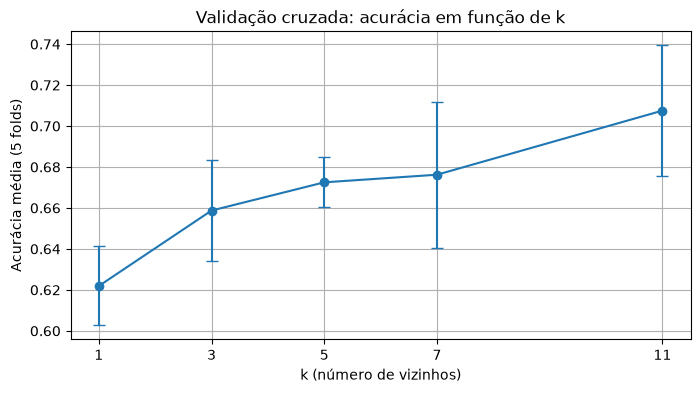

In [11]:
plt.errorbar(valores_k, acuracia_media, yerr=acuracia_desvio, marker='o', capsize=4)
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média (5 folds)")
plt.title("Validação cruzada: acurácia em função de k")
plt.xticks(valores_k)
plt.grid()
plt.savefig(f"{pasta_resultados}/acuracia_vs_k.png", dpi=150)
plt.show()

**Análise da escolha do k:** a acurácia média cresce com o `k`: vai de **0,622** (`k = 1`) até **0,708**
(`k = 11`), que foi o melhor valor testado.

* **k muito baixo (ex.: k = 1):** o modelo olha só **um** vizinho. Ele "decora" o treino e qualquer vinho
  atípico (ruído) muda a resposta. A fronteira de decisão fica cheia de recortes: é **overfitting**
  (alta variância). Por isso `k = 1` teve o pior resultado.
* **k muito alto:** a votação envolve muitos vizinhos, inclusive vinhos distantes e de outras classes. A fronteira
  fica suave demais e o modelo tende a responder sempre a **classe majoritária**: é **underfitting** (alto viés).
  No limite, com `k` igual ao tamanho do treino, ele preveria sempre "médio".
* O melhor `k` fica no meio-termo. Como a curva ainda subia em `k = 11` (o maior valor do enunciado), valores um
  pouco maiores poderiam ser testados.

Treinando o modelo final com o melhor `k`, agora usando **todo** o conjunto de treino:

In [12]:
modelo = KNeighborsClassifier(n_neighbors=melhor_k)
modelo.fit(X_train_sc, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['bom','médio','ruim']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 5. Tarefa 4 - Avaliação no conjunto de teste

In [13]:
y_pred = modelo.predict(X_test_sc)
classes = ["ruim", "médio", "bom"]

print(f"Acurácia no teste: {accuracy_score(y_test, y_pred):.4f}")

Acurácia no teste: 0.7537


**Matriz de confusão** (linhas = classe real, colunas = classe prevista):

             prev: ruim  prev: médio  prev: bom
real: ruim           91           37          0
real: médio          27          114          0
real: bom             0            3          0


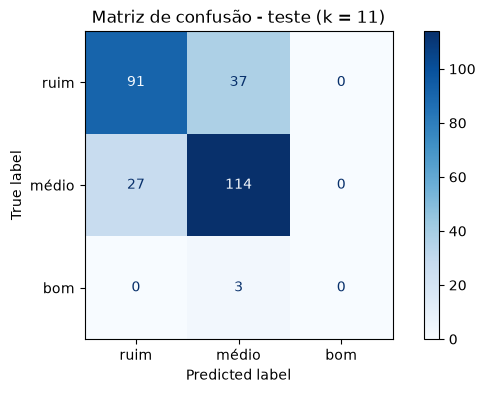

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
print(pd.DataFrame(cm, index=[f"real: {c}" for c in classes], columns=[f"prev: {c}" for c in classes]))

ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues")
plt.title(f"Matriz de confusão - teste (k = {melhor_k})")
plt.savefig(f"{pasta_resultados}/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

**Precisão, recall e F1-score de cada classe.** A coluna `support` é a quantidade de vinhos de cada classe no
teste. O `zero_division=0` evita um aviso caso o modelo nunca preveja alguma classe.

In [15]:
print(classification_report(y_test, y_pred, labels=classes, digits=4, zero_division=0))

              precision    recall  f1-score   support

        ruim     0.7712    0.7109    0.7398       128
       médio     0.7403    0.8085    0.7729       141
         bom     0.0000    0.0000    0.0000         3

    accuracy                         0.7537       272
   macro avg     0.5038    0.5065    0.5042       272
weighted avg     0.7466    0.7537    0.7488       272



## 6. Conclusão

**Entre quais classes o modelo erra com mais frequência?** Entre **ruim** e **médio**: 37 vinhos ruins foram
classificados como médios e 27 médios como ruins (64 dos 67 erros). Isso faz sentido: as duas classes ficam
**lado a lado** na escala de notas (5 e 6), e vinhos com nota 5 e 6 têm composições químicas parecidas.

**A classe "bom" nunca foi prevista** (recall = 0). Os 3 vinhos bons do teste foram classificados como médios.
O motivo é o **desbalanceamento**: só 17 vinhos bons em 1.359 (1,3%). Com `k = 11`, para um vinho ser chamado de
"bom", a maioria dos 11 vizinhos teria que ser "bom", o que quase nunca acontece, porque os bons são poucos e
ficam misturados aos médios.

| Classe | Precisão | Recall | F1-score | Vinhos no teste |
|---|---|---|---|---|
| ruim | 0,771 | 0,711 | 0,740 | 128 |
| médio | 0,740 | 0,809 | 0,773 | 141 |
| bom | 0,000 | 0,000 | 0,000 | 3 |

**Acurácia no teste: 0,754.** Ela parece razoável, mas esconde o fracasso na classe "bom". Para melhorar essa
classe seria preciso tratar o desbalanceamento (por exemplo, com SMOTE, visto em aula, ou usando votação com
peso pela distância).